# RQ1 Part A: did Japan's inflation change?

- Bai–Perron break tests on the target's average (level) and on the size of its monthly moves (volatility), Jan 2007 to Aug 2026. 

- rules: 5% tests, 15% trimming (each regime at least 35 months), at most 5 breaks (15% trimming rules data only enouugh for 6 regime) 
- HAC standard errors with 12 lags.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xtbreak
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"

START = "2007-01"
TRIM = 0.15     # each regime at least 15% of the sample
HAC_LAGS = 12   # neighbouring YoY rates share 11 months
MAX_BREAKS = 5  # we only have 236 months,so 5 breaks is the most we can test in 15% trimming rules.
# 5% critical values for "one more break?" (sup-F(l+1|l)), testing a change in the
# average only, 15% trimming. Source: Bai and Perron (2003), Econometrics Journal 6.
CRITICAL_5PCT = {1: 8.58, 2: 10.13, 3: 11.14, 4: 11.83, 5: 12.25}

## 1. The data
Two series: 
- Target itself (level)
- Size of each monthly move = [inflation this month − inflation last month] (volatility).

In [13]:
data = pd.read_csv(ROOT / "data" / "processed" / "target.csv")
data["level"] = data["target"]
data["volatility"] = data["target"].diff().abs()  # Jan 2007 uses Dec 2006
data = data[data["month"] >= START].reset_index(drop=True)
months = data["month"].tolist()

# Check: starts in Jan 2007, one row per month, nothing missing
month_number = data["month"].str[:4].astype(int) * 12 + data["month"].str[5:].astype(int)
assert months[0] == "2007-01" and (month_number.diff().dropna() == 1).all()
assert data[["level", "volatility"]].notna().all().all()

print(len(data), "months:", months[0], "to", months[-1])
data[["month", "level", "volatility"]]

236 months: 2007-01 to 2026-08


,month,level,volatility
0,2007-01,-0.1,0.1
1,2007-02,-0.1,0.0
2,2007-03,-0.1,0.0
3,2007-04,-0.1,0.0
4,2007-05,-0.1,0.0
...,...,...,...
231,2026-04,2.2,0.3
232,2026-05,2.1,0.1
233,2026-06,2.0,0.1
234,2026-07,2.2,0.2


## 2. One break? The Chow test at every month (sup-F)

Chow test at every month except the first and last 15%: 167 months, Dec 2009 to Oct 2023. Then two steps:
1. **Is there a break?** Take the largest F (sup-F). If it is above 8.58, yes. (8.58, not 3.84, because we searched many months.)
2. **When?** Only if step 1 says yes: the break date is the month with the smallest SSR, the split that fits the data best. This is the final answer for the date.

In [14]:
def chow_f(y, k):
    """Chow test for a change in the average at position k, with HAC errors."""
    dummy = (np.arange(len(y)) >= k).astype(float)
    fit = OLS(y, add_constant(dummy)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    return fit.tvalues[1] ** 2


def ssr_split(y, k):
    """Sum of squared residuals when the average is allowed to change at position k."""
    before, after = y[:k], y[k:]
    return ((before - before.mean()) ** 2).sum() + ((after - after.mean()) ** 2).sum()


def sup_f(y, min_len):
    """Chow test at every allowed position: the largest F, the best position (smallest SSR), all F values."""
    positions = list(range(min_len, len(y) - min_len + 1))
    f_values = [chow_f(y, k) for k in positions]
    best_k = min(positions, key=lambda k: ssr_split(y, k))
    return max(f_values), best_k, pd.Series(f_values, index=positions)


y = data["level"].to_numpy()
MIN_LEN = int(TRIM * len(y))  # 35 months
largest_f, best_k, f_path = sup_f(y, MIN_LEN)
print("sup-F (the largest F):", round(largest_f, 1), "at", months[f_path.idxmax()],
      "  5% critical value:", CRITICAL_5PCT[1])
print("Best single break (smallest SSR):", months[best_k])

# Every month tested, with its F and its SSR, sorted by SSR.
# The first row is the chosen break: the split that fits the data best.
f_by_month = pd.Series(f_path.values, index=[months[k] for k in f_path.index])
all_months = pd.DataFrame({"F": f_by_month, "SSR": [ssr_split(y, k) for k in f_path.index]})
print(len(all_months), "months tested:", all_months.index[0], "to", all_months.index[-1])
all_months.sort_values("SSR").round(1)

sup-F (the largest F): 99.4 at 2022-08   5% critical value: 8.58
Best single break (smallest SSR): 2022-07
167 months tested: 2009-12 to 2023-10


,F,SSR
2022-07,97.8,112.5
2022-08,99.4,112.7
2022-06,93.8,113.2
2022-09,98.6,114.6
2022-05,87.7,115.0
...,...,...
2010-04,4.0,403.3
2010-03,3.7,406.2
2010-02,3.4,408.9
2010-01,3.2,411.5


### Check our loop

Two checks before we trust it. 
- 1)On made-up data with a known jump at month 100, the loop must find month 100. 
- 2)On the real target, it must pick the same single break as xtbreak, which finds the best break dates by a different method (dynamic programming).

In [15]:
def best_breaks(y, m):
    """Best m break positions chosen together (xtbreak), with 95% intervals.
    Each position is the first month of a new regime."""
    result = xtbreak.estimate(y, np.ones((len(y), 1)), breaks=m, trimming=TRIM)
    return [(b.index, b.ci_index[0], b.ci_index[1]) for b in result.break_estimates]


# Made-up series: average 0 for 100 months, then 2 for 100 months, plus noise
rng = np.random.default_rng(1)
fake = np.r_[np.zeros(100), np.full(100, 2.0)] + rng.normal(0, 0.3, 200)
assert sup_f(fake, 30)[1] == 100

# Our loop and xtbreak agree on the real target
assert best_k == best_breaks(y, 1)[0][0]
print("ok")

ok


## 3. More than one break: the Bai–Perron loop

The same two steps, repeated:
1. **One more break?** sup-F inside each regime (critical values 10.13, 11.14, 11.83).
2. **When?** If yes, the smallest total SSR dates all the breaks together (`break_dates`).

The loop stops at the first "no". The final dates come from the last "yes" round.

In [16]:
def find_breaks(y):
    """Bai-Perron sequential test: add one break at a time while the test says yes."""
    breaks, tests = [], []
    for l in range(MAX_BREAKS):
        # Split at the current breaks and test each regime for one more break
        edges = [0] + [b[0] for b in breaks] + [len(y)]
        stat = 0.0
        for a, b in zip(edges[:-1], edges[1:]):
            if b - a >= 2 * MIN_LEN:  # only regimes long enough to split
                stat = max(stat, sup_f(y[a:b], MIN_LEN)[0])
        crit = CRITICAL_5PCT[l + 1]
        row = {"test": f"{l} vs {l + 1} breaks", "sup_F": round(stat, 1),
               "critical(5%)": crit, "reject": stat > crit, "break_dates": ""}
        tests.append(row)
        if stat <= crit:
            break
        breaks = best_breaks(y, l + 1)
        # The dates of all breaks after this round (each is the first month of a new regime)
        row["break_dates"] = ", ".join(months[b[0]] for b in breaks)
    return breaks, tests


breaks, tests = find_breaks(y)
pd.DataFrame(tests)

,test,sup_F,critical(5%),reject,break_dates
0,0 vs 1 breaks,99.4,8.58,True,2022-07
1,1 vs 2 breaks,11.6,10.13,True,"2013-10, 2022-08"
2,2 vs 3 breaks,12.0,11.14,True,"2010-01, 2013-07, 2022-08"
3,3 vs 4 breaks,5.6,11.83,False,


## Each regime with its average. 
- `start_low` and `start_high` are xtbreak's 95% interval for the month the regime starts. 
- They ignore serial correlation, so they are probably too narrow.

In [17]:
def regime_table(name, y, breaks):
    """One row per regime: first and last month, length, average, 95% interval for its start."""
    edges = [0] + [b[0] for b in breaks] + [len(y)]
    rows = []
    for i, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        row = {"series": name, "regime": i + 1, "start": months[a], "end": months[b - 1],
               "months": b - a, "average": round(y[a:b].mean(), 2)}
        if i > 0:
            row["start_low"], row["start_high"] = months[breaks[i - 1][1]], months[breaks[i - 1][2]]
        rows.append(row)
    return rows


level_regimes = regime_table("level", y, breaks)
pd.DataFrame(level_regimes)

,series,regime,start,end,months,average,start_low,start_high
0,level,1,2007-01,2009-12,36,0.11,NaN,NaN
1,level,2,2010-01,2013-06,42,-0.79,2009-06,2010-08
2,level,3,2013-07,2022-07,109,0.50,2013-05,2013-09
3,level,4,2022-08,2026-08,49,2.99,2022-06,2022-10


## 4. Volatility: the size of the monthly moves

The same test, on the second series.

In [18]:
v = data["volatility"].to_numpy()
v_breaks, v_tests = find_breaks(v)
volatility_regimes = regime_table("volatility", v, v_breaks)

display(pd.DataFrame(v_tests))
pd.DataFrame(volatility_regimes)

,test,sup_F,critical(5%),reject,break_dates
0,0 vs 1 breaks,16.8,8.58,True,2022-03
1,1 vs 2 breaks,12.2,10.13,True,"2014-01, 2022-03"
2,2 vs 3 breaks,2.2,11.14,False,


,series,regime,start,end,months,average,start_low,start_high
0,volatility,1,2007-01,2013-12,84,0.13,NaN,NaN
1,volatility,2,2014-01,2022-02,98,0.08,2008-12,2019-02
2,volatility,3,2022-03,2026-08,54,0.18,2020-04,2024-02


### Check the rules

- Maximum 5 breaks only, every regime at least 35 months long
- One break for each "yes", and every month in exactly one regime.

In [19]:
for b, t, regimes in [(breaks, tests, level_regimes), (v_breaks, v_tests, volatility_regimes)]:
    edges = [0] + [x[0] for x in b] + [len(data)]
    assert len(b) <= MAX_BREAKS
    assert all(end - start >= MIN_LEN for start, end in zip(edges[:-1], edges[1:]))
    assert len(b) == sum(row["reject"] for row in t)
    assert sum(r["months"] for r in regimes) == len(data)
print("ok")

ok


## 5. Save the two tables

In [20]:
tests_table = pd.DataFrame([{"series": "level", **t} for t in tests]
                           + [{"series": "volatility", **t} for t in v_tests])
regimes_table = pd.DataFrame(level_regimes + volatility_regimes)

TABLES.mkdir(parents=True, exist_ok=True)
tests_table.to_csv(TABLES / "rq1_tests.csv", index=False)
regimes_table.to_csv(TABLES / "rq1_regimes.csv", index=False)
print("Saved results/tables/rq1_tests.csv and results/tables/rq1_regimes.csv")

Saved results/tables/rq1_tests.csv and results/tables/rq1_regimes.csv


## 6. Chart: breaks in the level and the volatility

Same plain style as the README chart.

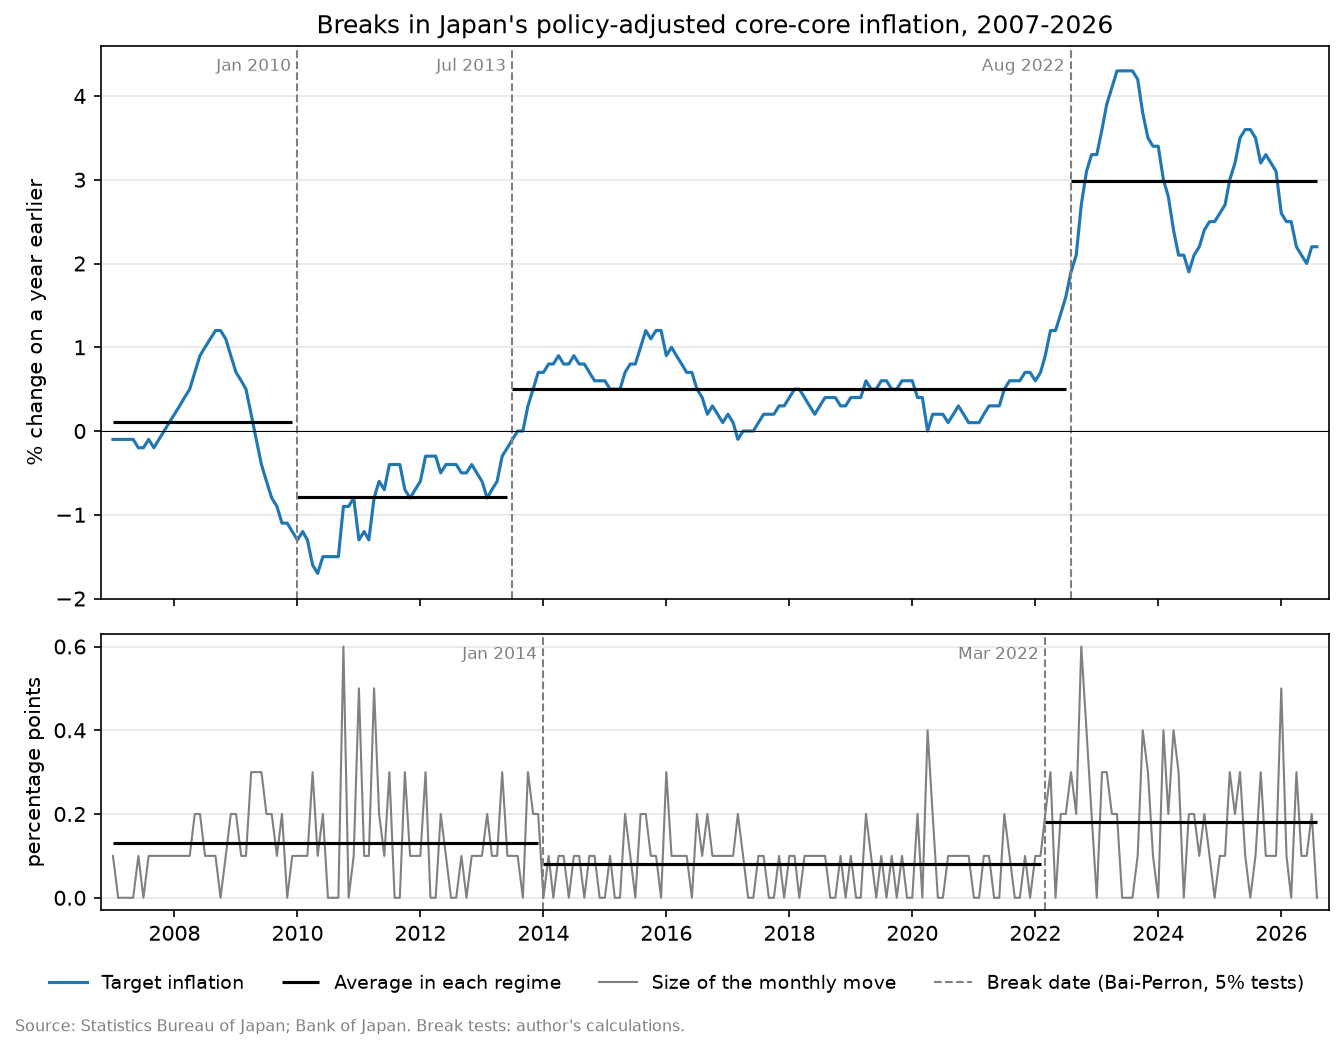

In [21]:
SOURCE = "Source: Statistics Bureau of Japan; Bank of Japan. Break tests: author's calculations."
dates = pd.to_datetime(data["month"])


def draw_regimes(ax, regimes, label):
    """Black line for each regime's average, grey dashed line and label at each break."""
    for r in regimes:
        start, end = pd.Timestamp(r["start"]), pd.Timestamp(r["end"])
        ax.hlines(r["average"], start, end, color="black", linewidth=1.5,
                  label=label if r["regime"] == 1 else None)
        if r["regime"] > 1:
            ax.axvline(start, color="gray", linestyle="--", linewidth=1)
            ax.annotate(f"{start:%b %Y}", xy=(start, 1.0), xycoords=("data", "axes fraction"),
                        xytext=(-3, -12), textcoords="offset points", ha="right", fontsize=8, color="gray")


fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7), dpi=150, sharex=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
top.plot(dates, data["level"], color="tab:blue", linewidth=1.5, label="Target inflation")
draw_regimes(top, level_regimes, "Average in each regime")
top.axhline(0, color="black", linewidth=0.5)
top.set_title("Breaks in Japan's policy-adjusted core-core inflation, 2007-2026")
top.set_ylabel("% change on a year earlier")

bottom.plot(dates, data["volatility"], color="gray", linewidth=1, label="Size of the monthly move")
draw_regimes(bottom, volatility_regimes, "Average in each regime")
bottom.set_ylabel("percentage points")

for ax in (top, bottom):
    ax.grid(axis="y", alpha=0.3)
    ax.margins(x=0.01)
# One legend for both panels, below the chart
handles = top.get_legend_handles_labels()[0] + bottom.get_legend_handles_labels()[0][:1]
handles.append(plt.Line2D([], [], color="gray", linestyle="--", linewidth=1,
                          label="Break date (Bai-Perron, 5% tests)"))
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.03), ncol=4, frameon=False, fontsize=9)
fig.text(0.01, 0.01, SOURCE, fontsize=7.5, color="gray")
fig.tight_layout(rect=(0, 0.07, 1, 1))

FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "rq1_breaks.png")
plt.show()

## 7. Chart: the Chow test at every month

Section 2's F at each month. It shows step 1 (is there a break?), not the date.

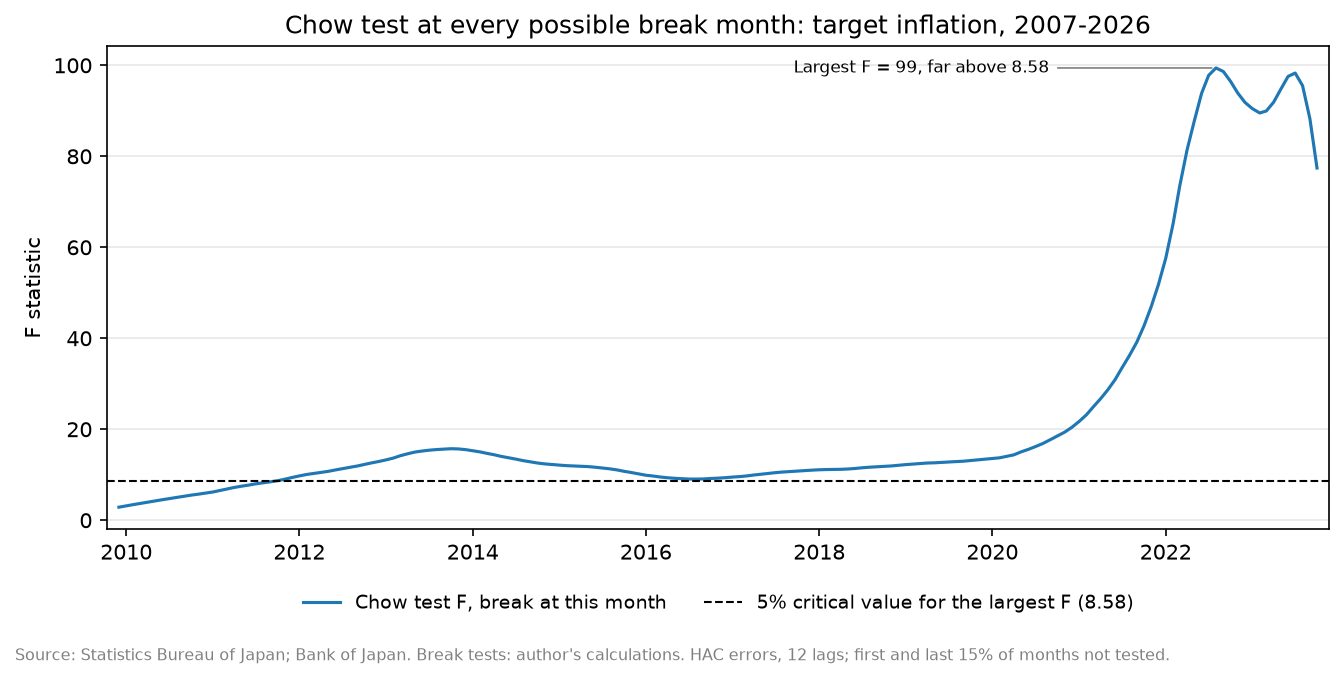

In [22]:
peak = pd.Timestamp(f_by_month.idxmax())  # month with the largest F

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
ax.plot(pd.to_datetime(f_by_month.index), f_by_month.values, color="tab:blue",
        label="Chow test F, break at this month")
ax.axhline(CRITICAL_5PCT[1], color="black", linestyle="--", linewidth=1,
           label=f"5% critical value for the largest F ({CRITICAL_5PCT[1]})")
ax.annotate(f"Largest F = {largest_f:.0f}, far above {CRITICAL_5PCT[1]}", xy=(peak, largest_f),
            xytext=(-80, 0), textcoords="offset points", ha="right", va="center", fontsize=8,
            arrowprops=dict(arrowstyle="-", color="gray", linewidth=0.8))
ax.set_title("Chow test at every possible break month: target inflation, 2007-2026")
ax.set_ylabel("F statistic")
ax.grid(axis="y", alpha=0.3)
ax.margins(x=0.01)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=9)
fig.text(0.01, 0.01, SOURCE + " HAC errors, 12 lags; first and last 15% of months not tested.",
         fontsize=7.5, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIGURES / "rq1_chow_path.png")
plt.show()